In [ ]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
#1.准备四个特征（面积，房间数，卫生间数，楼层）
X = np.array([[50, 3, 2, 1],
              [60, 4, 3, 2],
              [70, 3, 2, 1],    
              [80, 4, 3, 2],
              [90, 3, 2, 1],
              [100, 4, 3, 2],
              [110, 3, 2, 1],
              [120, 4, 3, 2],
              [130, 3, 2, 1],
              [140, 4, 3, 2]
              
])
y=np.array([120, 150, 130, 140, 160, 180, 200, 220, 240, 260])#目标变量（房价）

#2.训练模型
model = LinearRegression()
model.fit(X, y)
#3.查看学到的权重
feature_names = ['面积', '房间数', '卫生间数', '楼层']
print('各个特征权重：')
for name, weight in zip(feature_names, model.coef_):
    print(f'{name}: {weight:.3f}')
print(f'偏置 b: {model.intercept_:.3f}')

#4.评估模型
print(f'均方误差 (MSE): {mean_squared_error(y, model.predict(X)):.3f}')
print(f'R² 系数: {model.score(X, y):.3f}')

#5.预测
y_pred = model.predict(X)
print('预测房价：')
print(y_pred)

各个特征权重：
面积: 1.525
房间数: 1.583
卫生间数: 1.583
楼层: 1.583
偏置 b: 23.250
均方误差 (MSE): 139.500
R² 系数: 0.934
预测房价：
[109.  129.  139.5 159.5 170.  190.  200.5 220.5 231.  251. ]


d:\anaconda3\envs\aling\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\aling\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 27491 (\N{CJK UNIFIED IDEOGRAPH-6B63}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\aling\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 29575 (\N{CJK UNIFIED IDEOGRAPH-7387}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\aling\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 21484 (\N{CJK UNIFIED IDEOGRAPH-53EC}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
d:\anaconda3\envs\aling\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 22238 (\N{CJK UNIFIED IDEOGRAPH-56DE}) missing from font(s) DejaVu Sans.
  

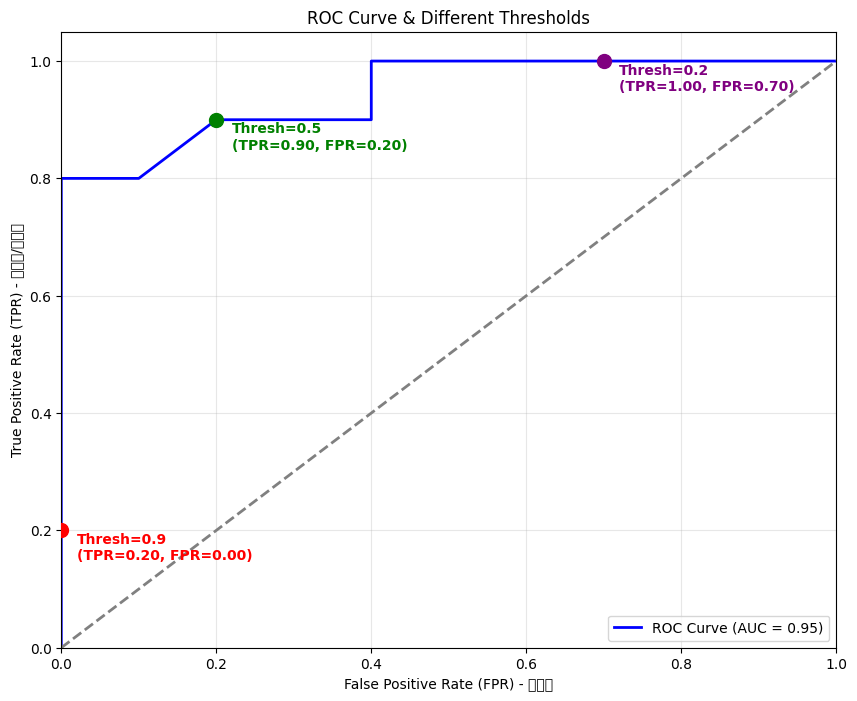

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, confusion_matrix

# 1. 模拟预测结果 (真实标签 y_true 和 模型预测概率 y_scores)
# 假设有 20 个样本，1代表正类，0代表负类
y_true = np.array([0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0])
# 模型的预测概率 (0 到 1 之间)
y_scores = np.array([0.1, 0.4, 0.35, 0.8, 0.2, 0.9, 0.5, 0.6, 0.7, 0.3, 
                     0.15, 0.85, 0.45, 0.75, 0.65, 0.95, 0.25, 0.55, 0.5, 0.05])

# 2. 计算 FPR, TPR 和 阈值
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 3. 选择几个不同的阈值作为演示
# 分别选一个非常严格的阈值 (0.9)，一个均衡的阈值 (0.5)，一个宽松的阈值 (0.2)
test_thresholds = [0.9, 0.5, 0.2]
colors = ['red', 'green', 'purple']

# 4. 画图
plt.figure(figsize=(10, 8))

# 画出 ROC 曲线本身
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC Curve (AUC = {roc_auc:.2f})')

# 遍历不同的阈值，在图上标出对应的点
for thresh, color in zip(test_thresholds, colors):
    # 根据阈值将概率转化为预测类别 (大于等于阈值为1，否则为0)
    y_pred = (y_scores >= thresh).astype(int)
    
    # 计算该阈值下的 TPR (召回率) 和 FPR
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    current_tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    current_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    # 在图上画一个点
    plt.scatter(current_fpr, current_tpr, color=color, s=100, zorder=5)
    plt.text(current_fpr + 0.02, current_tpr - 0.05, f'Thresh={thresh}\n(TPR={current_tpr:.2f}, FPR={current_fpr:.2f})', 
             color=color, fontsize=10, fontweight='bold')

# 画出对角线（随机猜测的基准线）
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR) - 假正率')
plt.ylabel('True Positive Rate (TPR) - 真正率/召回率')
plt.title('ROC Curve & Different Thresholds')
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

C:\Users\Administrator\AppData\Local\Temp\ipykernel_14216\602924065.py:55: UserWarning: Glyph 20005 (\N{CJK UNIFIED IDEOGRAPH-4E25}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_14216\602924065.py:55: UserWarning: Glyph 26684 (\N{CJK UNIFIED IDEOGRAPH-683C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_14216\602924065.py:55: UserWarning: Glyph 38408 (\N{CJK UNIFIED IDEOGRAPH-9608}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_14216\602924065.py:55: UserWarning: Glyph 20540 (\N{CJK UNIFIED IDEOGRAPH-503C}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_14216\602924065.py:55: UserWarning: Glyph 20445 (\N{CJK UNIFIED IDEOGRAPH-4FDD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\Administrator\AppData\Local\Temp\ipykernel_14216\60

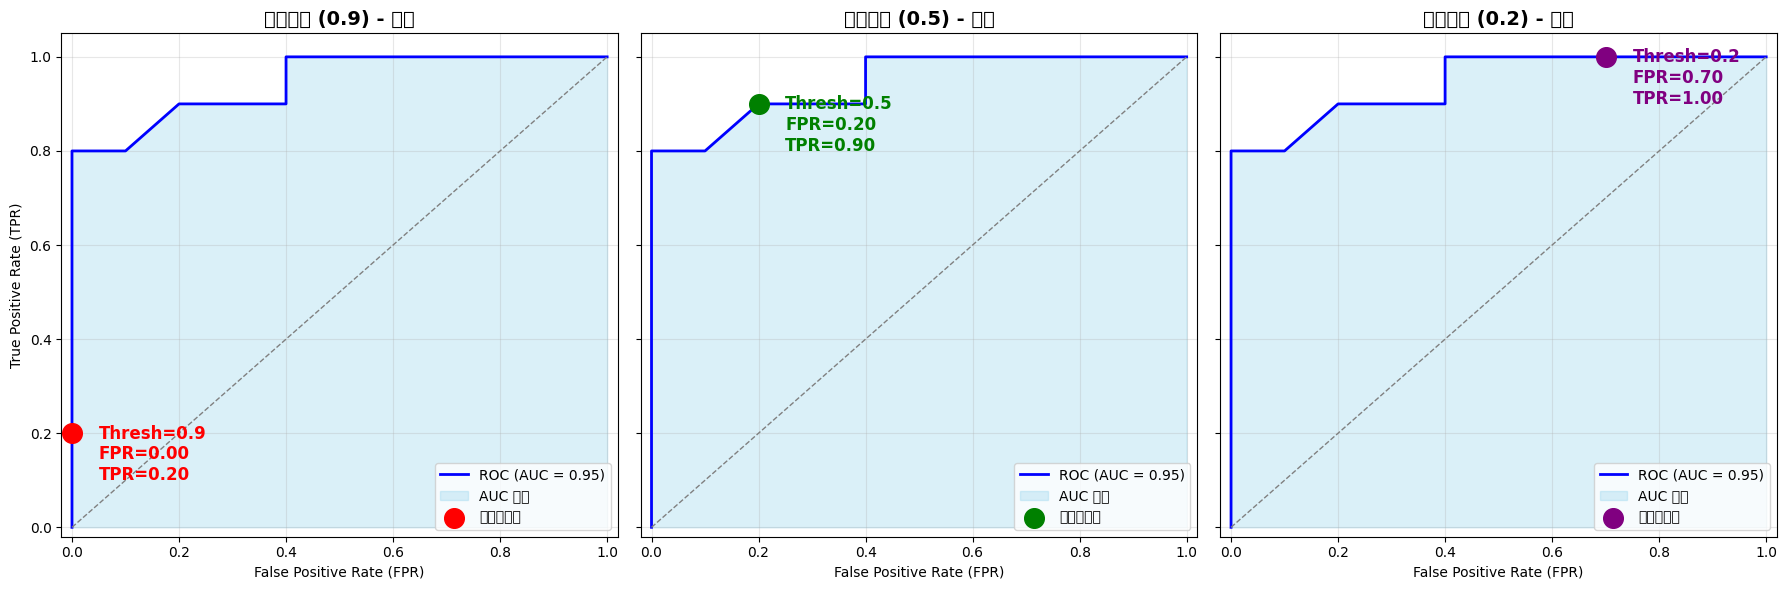

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc, confusion_matrix

# 1. 模拟数据
y_true = np.array([0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0])
y_scores = np.array([0.1, 0.4, 0.35, 0.8, 0.2, 0.9, 0.5, 0.6, 0.7, 0.3, 
                     0.15, 0.85, 0.45, 0.75, 0.65, 0.95, 0.25, 0.55, 0.5, 0.05])

# 2. 计算 ROC 和 AUC
fpr, tpr, thresholds = roc_curve(y_true, y_scores)
roc_auc = auc(fpr, tpr)

# 3. 设置要演示的三个阈值
test_threshs = [0.9, 0.5, 0.2]
titles = ['严格阈值 (0.9) - 保守', '均衡阈值 (0.5) - 常规', '宽松阈值 (0.2) - 激进']
colors = ['red', 'green', 'purple']

# 4. 创建画布 (1行3列的子图)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for i, (thresh, title, color) in enumerate(zip(test_threshs, titles, colors)):
    ax = axes[i]
    
    # 绘制 ROC 曲线
    ax.plot(fpr, tpr, color='blue', lw=2, label=f'ROC (AUC = {roc_auc:.2f})')
    # 用浅蓝色填充 AUC 面积
    ax.fill_between(fpr, tpr, color='skyblue', alpha=0.3, label='AUC 面积')
    # 绘制随机猜测对角线
    ax.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--')
    
    # 根据当前阈值计算对应的 FPR 和 TPR
    y_pred = (y_scores >= thresh).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    current_tpr = tp / (tp + fn) if (tp + fn) > 0 else 0
    current_fpr = fp / (fp + tn) if (fp + tn) > 0 else 0
    
    # 在曲线上标出当前阈值的点
    ax.scatter(current_fpr, current_tpr, color=color, s=200, zorder=5, label=f'当前工作点')
    # 添加文字标注
    ax.text(current_fpr + 0.05, current_tpr - 0.1, 
            f'Thresh={thresh}\nFPR={current_fpr:.2f}\nTPR={current_tpr:.2f}', 
            color=color, fontsize=12, fontweight='bold')
    
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('False Positive Rate (FPR)')
    if i == 0:
        ax.set_ylabel('True Positive Rate (TPR)')
    ax.set_xlim([-0.02, 1.02])
    ax.set_ylim([-0.02, 1.05])
    ax.legend(loc="lower right")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()